Failed to download left10.jpg: HTTP Error 404: Not Found
Failed to download right10.jpg: HTTP Error 404: Not Found


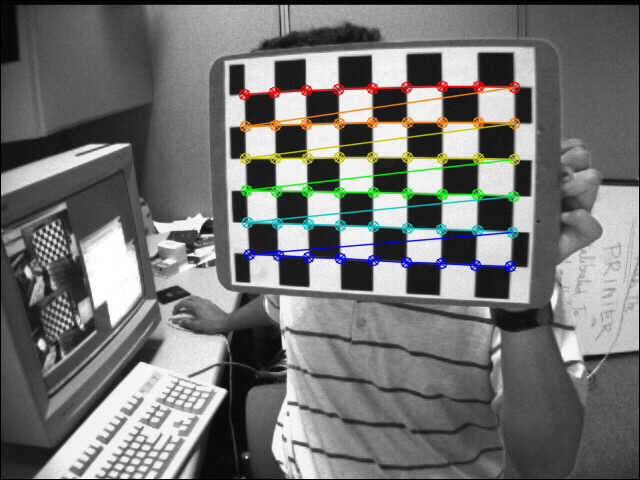

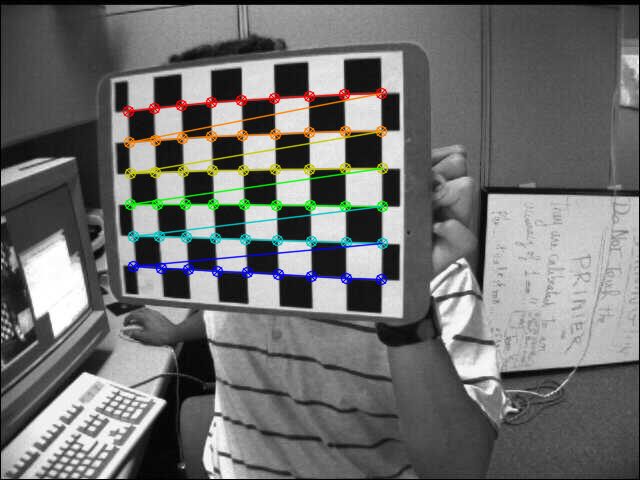

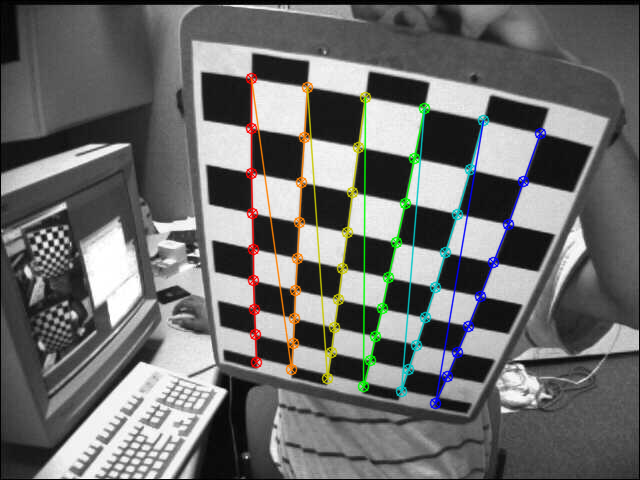

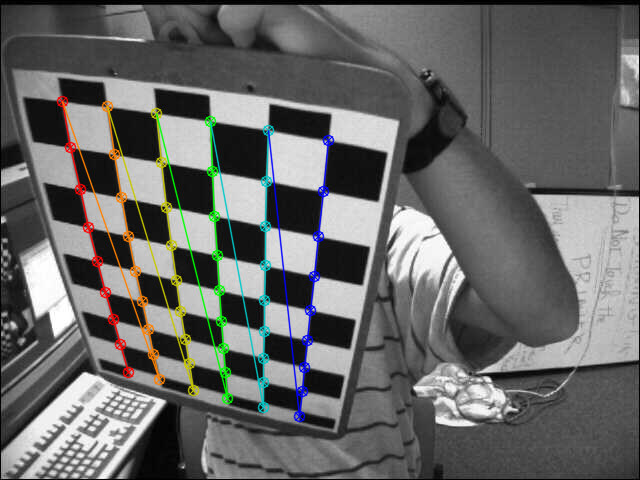

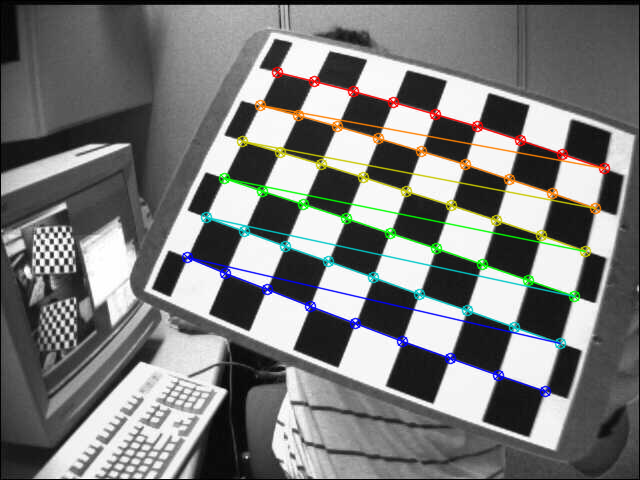

...

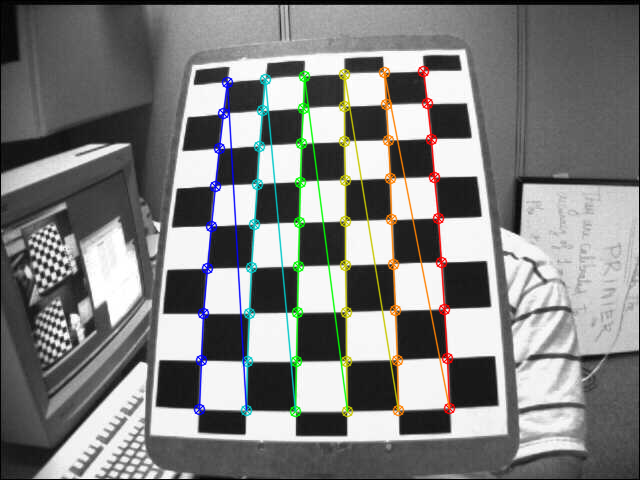

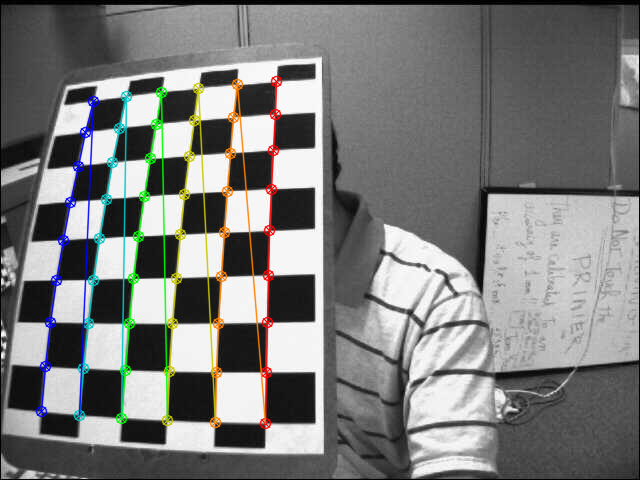

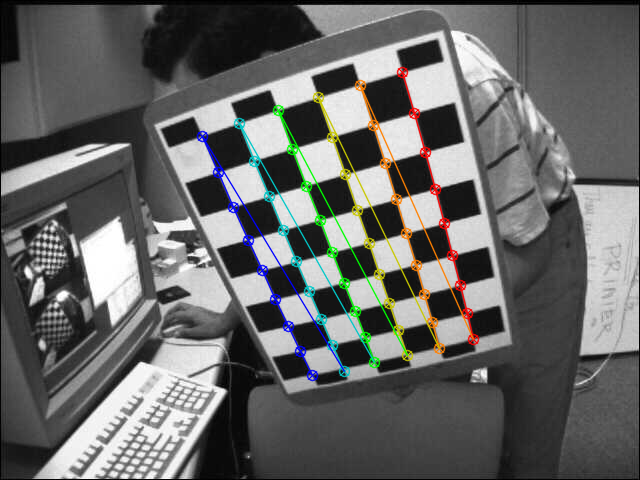

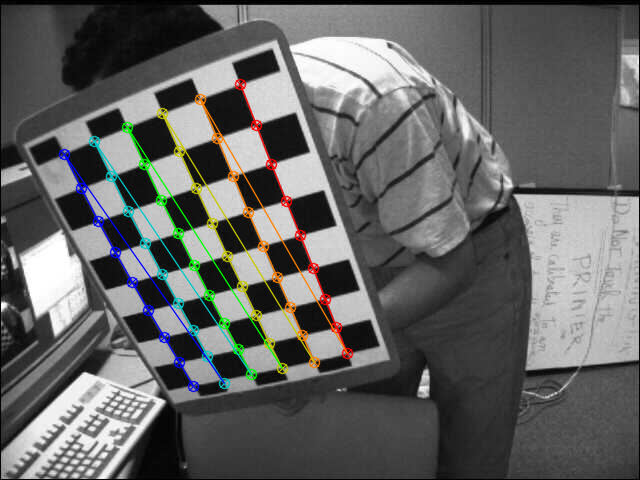

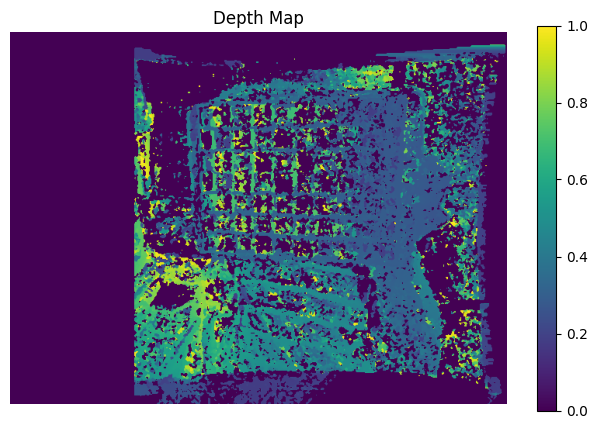

In [ ]:
import cv2
import numpy as np
import glob
import os
import urllib.request
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow  # Colab-specific image display

#os.makedirs("stereo_images/left")
#os.makedirs("stereo_images/right")

image_ids = [f"{i:02d}" for i in range(1, 14)]
base_url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/"

for img_id in image_ids:
    for side in ["left", "right"]:
        filename = f"{side}{img_id}.jpg"
        url = base_url + filename
        path = f"stereo_images/{side}/{filename}"
        if not os.path.exists(path):
            print(f"Downloading {filename}...")
            try:
                urllib.request.urlretrieve(url, path)
            except Exception as e:
                print(f"Failed to download {filename}: {e}")


def stereo_calibration():
    chessboardSize = (9, 6)
    frameSize = (640, 480)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)

    objp = np.zeros((chessboardSize[0] * chessboardSize[1], 3), np.float32)
    objp[:, :2] = np.mgrid[0:chessboardSize[0], 0:chessboardSize[1]].T.reshape(-1, 2)
    objp = objp * 20

    objpoints, imgpointsL, imgpointsR = [], [], []

    imagesLeft = sorted(glob.glob('stereo_images/left/*.jpg'))
    imagesRight = sorted(glob.glob('stereo_images/right/*.jpg'))

    for imgLeft, imgRight in zip(imagesLeft, imagesRight):
        imgL = cv2.imread(imgLeft)
        imgR = cv2.imread(imgRight)
        if imgL is None or imgR is None:
            continue

        grayL = cv2.cvtColor(imgL, cv2.COLOR_BGR2GRAY)
        grayR = cv2.cvtColor(imgR, cv2.COLOR_BGR2GRAY)

        retL, cornersL = cv2.findChessboardCorners(grayL, chessboardSize, None)
        retR, cornersR = cv2.findChessboardCorners(grayR, chessboardSize, None)

        if retL and retR:
            objpoints.append(objp)
            cornersL = cv2.cornerSubPix(grayL, cornersL, (11, 11), (-1, -1), criteria)
            cornersR = cv2.cornerSubPix(grayR, cornersR, (11, 11), (-1, -1), criteria)
            imgpointsL.append(cornersL)
            imgpointsR.append(cornersR)


            cv2_imshow(cv2.drawChessboardCorners(imgL.copy(), chessboardSize, cornersL, retL))
            cv2_imshow(cv2.drawChessboardCorners(imgR.copy(), chessboardSize, cornersR, retR))

    if len(objpoints) == 0:
        raise ValueError("No valid image pairs found for calibration")


    retL, cameraMatrixL, distL, _, _ = cv2.calibrateCamera(objpoints, imgpointsL, frameSize, None, None)
    retR, cameraMatrixR, distR, _, _ = cv2.calibrateCamera(objpoints, imgpointsR, frameSize, None, None)
    newCameraMatrixL, _ = cv2.getOptimalNewCameraMatrix(cameraMatrixL, distL, frameSize, 1, frameSize)
    newCameraMatrixR, _ = cv2.getOptimalNewCameraMatrix(cameraMatrixR, distR, frameSize, 1, frameSize)


    flags = 0
    criteria_stereo = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 50, 0.0001)
    retStereo, newCameraMatrixL, distL, newCameraMatrixR, distR, R, T, E, F = cv2.stereoCalibrate(
        objpoints, imgpointsL, imgpointsR, newCameraMatrixL, distL, newCameraMatrixR, distR,
        frameSize, criteria=criteria_stereo, flags=flags
    )

    rectifyScale = 1
    rectL, rectR, projMatrixL, projMatrixR, Q, roi_L, roi_R = cv2.stereoRectify(
        newCameraMatrixL, distL, newCameraMatrixR, distR, frameSize, R, T, alpha=rectifyScale, newImageSize=(0, 0)
    )
    stereoMapL = cv2.initUndistortRectifyMap(newCameraMatrixL, distL, rectL, projMatrixL, frameSize, cv2.CV_16SC2)
    stereoMapR = cv2.initUndistortRectifyMap(newCameraMatrixR, distR, rectR, projMatrixR, frameSize, cv2.CV_16SC2)

    cv_file = cv2.FileStorage('stereoMap.xml', cv2.FILE_STORAGE_WRITE)
    cv_file.write('stereoMapL_x', stereoMapL[0])
    cv_file.write('stereoMapL_y', stereoMapL[1])
    cv_file.write('stereoMapR_x', stereoMapR[0])
    cv_file.write('stereoMapR_y', stereoMapR[1])
    cv_file.write('Q', Q)
    cv_file.release()

    return stereoMapL, stereoMapR, Q


def test_disparity(stereoMapL, stereoMapR, Q):
    imgL = cv2.imread("stereo_images/left/left01.jpg")
    imgR = cv2.imread("stereo_images/right/right01.jpg")
    if imgL is None or imgR is None:
        raise FileNotFoundError("Failed to load test images")

    frameL = cv2.remap(imgL, stereoMapL[0], stereoMapL[1], cv2.INTER_LANCZOS4, cv2.BORDER_CONSTANT)
    frameR = cv2.remap(imgR, stereoMapR[0], stereoMapR[1], cv2.INTER_LANCZOS4, cv2.BORDER_CONSTANT)
    grayL = cv2.cvtColor(frameL, cv2.COLOR_BGR2GRAY)
    grayR = cv2.cvtColor(frameR, cv2.COLOR_BGR2GRAY)


    stereo = cv2.StereoSGBM_create(minDisparity=0, numDisparities=16*10, blockSize=3)
    disparity = stereo.compute(grayL, grayR).astype(np.float32) / 16.0

    # depth extraction
    disparity[disparity <= 0] = 0.1
    points_3d = cv2.reprojectImageTo3D(disparity, Q)
    depth_map = points_3d[:, :, 2]
    depth_map[depth_map <= 0] = 0
    depth_map[depth_map > 1000] = 1

    # Normalization
    mask = depth_map.astype(np.uint8) * 255
    depth_norm = cv2.normalize(depth_map, None, alpha=0, beta=1, norm_type=cv2.NORM_MINMAX, dtype=cv2.CV_32F, mask=mask)

    plt.figure(figsize=(8, 5))
    plt.imshow(depth_norm, cmap='viridis')
    plt.title("Depth Map")
    plt.colorbar()
    plt.axis('off')
    plt.show()


if __name__ == "__main__":
    stereoMapL, stereoMapR, Q = stereo_calibration()
    test_disparity(stereoMapL, stereoMapR, Q)